In [ ]:
# ==========================================
# COMMON SETUP — DATA LOADING & PREPROCESSING
# Run this once before any of the three baselines
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings('ignore')

# ── MOUNT DRIVE & AUTO-FIND FILE ──────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')

import os
search_root   = '/content/drive/MyDrive'
filename      = 'HF_DATASET.csv'
csv_file_path = None

for root, dirs, files in os.walk(search_root):
    for f in files:
        if f == filename:
            csv_file_path = os.path.join(root, f)
            break
    if csv_file_path:
        break

if csv_file_path is None:
    raise FileNotFoundError(f"'{filename}' not found in Google Drive.")

print(f"File found at: {csv_file_path}")

# ── LOAD & CLEAN DATA ─────────────────────────────────────────────────────────
df_raw = pd.read_csv(csv_file_path, header=None)

df_hdfc           = df_raw.iloc[:, 0:5].copy()
df_hdfc.columns   = ['Date', 'Close', 'Volume', 'High', 'Low']

df_icici          = df_raw.iloc[:, 6:11].copy()
df_icici.columns  = ['Date', 'Close', 'Volume', 'High', 'Low']

for df in [df_hdfc, df_icici]:
    df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
    for col in ['Close', 'Volume', 'High', 'Low']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df.dropna(inplace=True)
    df.set_index('Date', inplace=True)
    df.sort_index(inplace=True)

data = pd.merge(df_hdfc, df_icici, left_index=True, right_index=True, suffixes=('_HDFC', '_ICICI'))
data['Log_HDFC']  = np.log(data['Close_HDFC'])
data['Log_ICICI'] = np.log(data['Close_ICICI'])
data['Spread']    = data['Log_HDFC'] - data['Log_ICICI']

window = 30
data['Z_Score'] = (
    data['Spread'] - data['Spread'].rolling(window).mean()
) / data['Spread'].rolling(window).std()

data.dropna(inplace=True)

# ── TRAIN / TEST SPLIT ────────────────────────────────────────────────────────
split_date = '2023-01-01'
train_data = data[data.index < split_date].copy()
test_data  = data[data.index >= split_date].copy()

train_z = train_data['Z_Score'].values
test_z  = test_data['Z_Score'].values

print(f"Total rows      : {len(data)}")
print(f"Training rows   : {len(train_data)}")
print(f"Testing rows    : {len(test_data)}")
print("Setup complete — ready to run all three baselines.")

Mounted at /content/drive
File found at: /content/drive/MyDrive/Minor_project_dataset/HF_DATASET.csv
Total rows      : 3959
Training rows   : 3197
Testing rows    : 762
Setup complete — ready to run all three baselines.


In [ ]:
# ==========================================
# BASELINE 2: ARIMA MODEL
# Order (p=5, d=0, q=0) — Z-Score is already
# stationary so d=0. p=5 captures 5-day memory.
# Uses a rolling one-step-ahead forecast to
# match the LSTM's day-by-day prediction style.
# ==========================================

from statsmodels.tsa.arima.model import ARIMA

print("Fitting ARIMA — this may take 2–4 minutes due to rolling forecast...")

arima_pred   = []
arima_actual = []

# Rolling window forecast: train on all data up to day t, predict day t+1
# This is the academically correct way to evaluate ARIMA on time-series
history = list(train_z)

for t in range(len(test_z)):
    model  = ARIMA(history, order=(5, 0, 0))
    result = model.fit()
    yhat   = result.forecast(steps=1)[0]

    arima_pred.append(yhat)
    arima_actual.append(test_z[t])
    history.append(test_z[t])   # add real value to history for next step

    if t % 100 == 0:
        print(f"  Forecasting day {t}/{len(test_z)}...")

arima_pred   = np.array(arima_pred)
arima_actual = np.array(arima_actual)

print("ARIMA forecasting complete.")

Fitting ARIMA — this may take 2–4 minutes due to rolling forecast...
  Forecasting day 0/762...
  Forecasting day 100/762...
  Forecasting day 200/762...
  Forecasting day 300/762...
  Forecasting day 400/762...
  Forecasting day 500/762...
  Forecasting day 600/762...
  Forecasting day 700/762...
ARIMA forecasting complete.


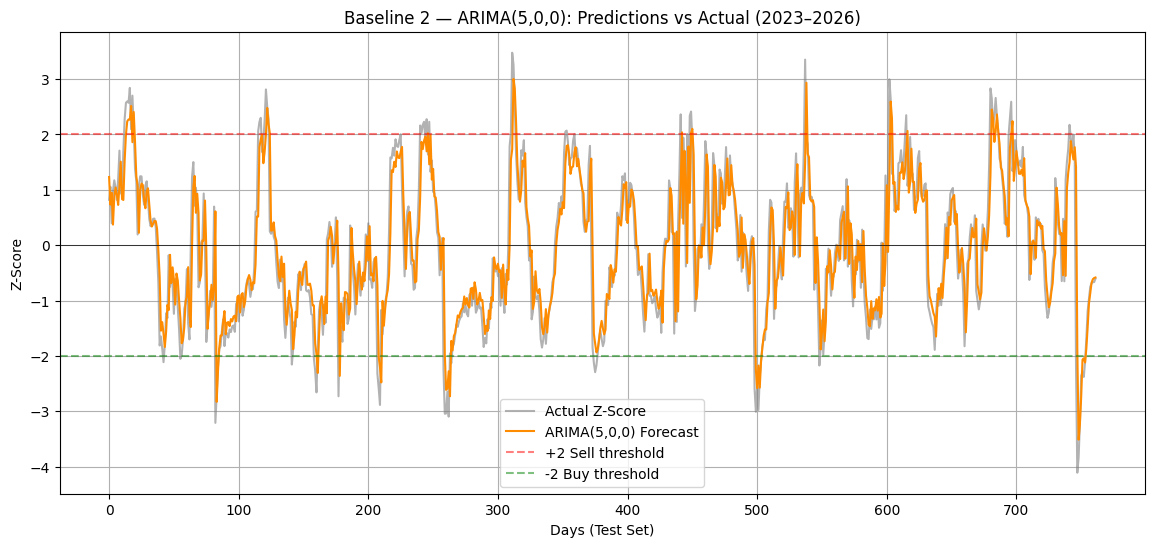

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(arima_actual, label='Actual Z-Score',    color='grey',  alpha=0.6)
plt.plot(arima_pred,   label='ARIMA(5,0,0) Forecast', color='darkorange', linewidth=1.5)
plt.axhline( 2.0, color='red',   linestyle='--', alpha=0.5, label='+2 Sell threshold')
plt.axhline(-2.0, color='green', linestyle='--', alpha=0.5, label='-2 Buy threshold')
plt.axhline( 0,   color='black', linewidth=0.5)
plt.title('Baseline 2 — ARIMA(5,0,0): Predictions vs Actual (2023–2026)')
plt.xlabel('Days (Test Set)')
plt.ylabel('Z-Score')
plt.legend()
plt.grid(True)
plt.show()

ARIMA RESULTS
Initial Capital : ₹100,000
Final Capital   : ₹136,024
Total Return    : 36.02%


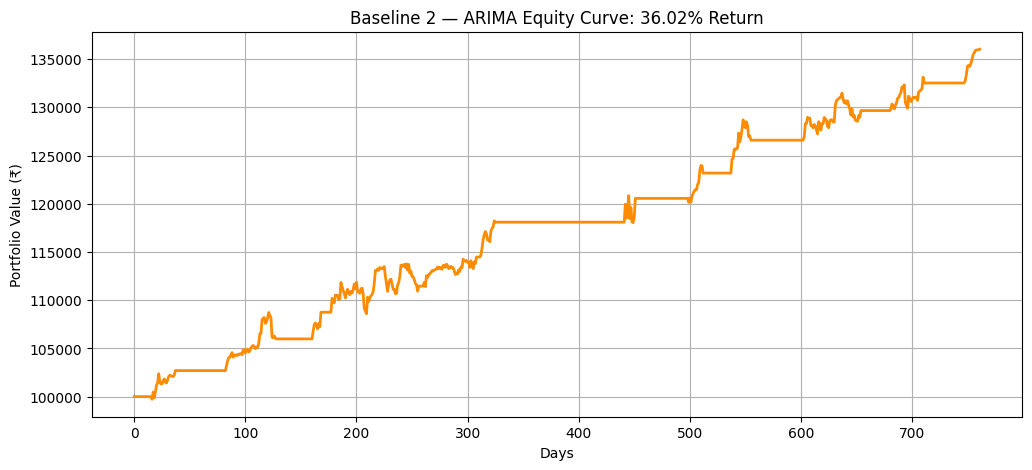

In [ ]:
ENTRY_THRESHOLD = 2.0
initial_capital = 100000
capital         = initial_capital
position        = 0
arima_equity    = []

for i in range(len(arima_pred)):
    z = arima_pred[i]

    if z > ENTRY_THRESHOLD and position == 0:
        position = -1
    elif z < -ENTRY_THRESHOLD and position == 0:
        position = 1
    elif abs(z) < 0.1 and position != 0:
        position = 0

    if i > 0:
        z_change      = arima_actual[i] - arima_actual[i-1]
        daily_profit  = position * z_change * 1000
        capital      += daily_profit

    arima_equity.append(capital)

arima_return = ((capital - initial_capital) / initial_capital) * 100

print(f"=================================")
print(f"ARIMA RESULTS")
print(f"Initial Capital : ₹{initial_capital:,}")
print(f"Final Capital   : ₹{int(capital):,}")
print(f"Total Return    : {arima_return:.2f}%")
print(f"=================================")

plt.figure(figsize=(12, 5))
plt.plot(arima_equity, color='darkorange', linewidth=2)
plt.title(f'Baseline 2 — ARIMA Equity Curve: {arima_return:.2f}% Return')
plt.xlabel('Days')
plt.ylabel('Portfolio Value (₹)')
plt.grid(True)
plt.show()

In [ ]:
equity_a      = np.array(arima_equity)
daily_ret_a   = (equity_a[1:] - equity_a[:-1]) / (equity_a[:-1] + 1e-9)
sharpe_a      = (np.mean(daily_ret_a) / (np.std(daily_ret_a) + 1e-9)) * np.sqrt(252)
running_max_a = np.maximum.accumulate(equity_a)
max_dd_a      = ((equity_a - running_max_a) / running_max_a).min() * 100
neg_ret_a     = daily_ret_a[daily_ret_a < 0]
sortino_a     = (np.mean(daily_ret_a) / (np.std(neg_ret_a) + 1e-9)) * np.sqrt(252) if len(neg_ret_a) > 0 else 0.0
cagr_a        = ((equity_a[-1] / equity_a[0]) ** (252 / len(equity_a)) - 1) * 100

mse_a  = mean_squared_error(arima_actual, arima_pred)
rmse_a = np.sqrt(mse_a)
mae_a  = mean_absolute_error(arima_actual, arima_pred)
r2_a   = r2_score(arima_actual, arima_pred)

print("=============================================")
print("  BASELINE 2: ARIMA — REPORT CARD")
print("=============================================")
print(f"  Net Profit    : ₹{int(equity_a[-1] - equity_a[0]):,}")
print(f"  Total Return  : {((equity_a[-1]-equity_a[0])/equity_a[0])*100:.2f}%")
print(f"  CAGR          : {cagr_a:.2f}%")
print(f"---------------------------------------------")
print(f"  Sharpe Ratio  : {sharpe_a:.4f}")
print(f"  Sortino Ratio : {sortino_a:.4f}")
print(f"  Max Drawdown  : {max_dd_a:.2f}%")
print(f"---------------------------------------------")
print(f"  MSE           : {mse_a:.5f}")
print(f"  RMSE          : {rmse_a:.5f}")
print(f"  MAE           : {mae_a:.5f}")
print(f"  R² Score      : {r2_a:.4f}")
print("=============================================")

  BASELINE 2: ARIMA — REPORT CARD
  Net Profit    : ₹36,024
  Total Return  : 36.02%
  CAGR          : 10.71%
---------------------------------------------
  Sharpe Ratio  : 1.9266
  Sortino Ratio : 2.0086
  Max Drawdown  : -2.93%
---------------------------------------------
  MSE           : 0.39664
  RMSE          : 0.62979
  MAE           : 0.44253
  R² Score      : 0.7645
